# 03 · RQ1: Does Brent switch between a calm and a turbulent regime?

**The question in one sentence.** Do weekly Brent returns look like they come from two different "moods" of the market, a calm one and a turbulent one, instead of one stable pattern? And if so, how are the two moods different?

**The model (M1), in words.** Every week the market is in one of two hidden regimes: **N** (normal, calm) or **H** (high volatility, turbulent). We never see the regime directly; the model works out the *probability* of each regime from the returns. In each regime, this week's return is

  r(t) = μ(S) + φ(S) · r(t−1) + ε(t)

| Piece | What it means |
|---|---|
| r(t) | this week's Brent return, in % |
| S | the regime this week (N or H) |
| μ(S) | the average weekly return in that regime |
| φ(S) | how much of last week's return carries over to this week (close to 0 = almost no memory) |
| ε(t) | the "surprise" part of the return: normally distributed, average 0 |
| σ²(S) | the variance of the surprise in that regime: **this is what makes a regime calm (small) or turbulent (big)** |

Each week the regime either stays the same or switches. In M1 the chance of switching is a fixed number; it does not depend on any news. The regime with the bigger σ² is always called **H**.

**Which years:** only 2005–2018 (729 weeks). 2019 onwards is kept aside to test forecasts later, so nothing decided here has "seen" those years.

**What the notebook does**
1. Load the data and save the reference numbers that are used later to z-score variables.
2. Fit M1 and describe the two regimes.
3. Test: are two regimes really better than one?
4. Test: do μ and φ differ between the regimes? This gives **the φ decision**, which you confirm.
5. Rehearsal: fit the bigger models M2 and M3 on 2005–2018, before notebook 04 uses them for real.
6. Check that our own forecasting code gives exactly the same numbers as statsmodels.
7. Save the tables.
8. Automatic checks.

**Files it writes:** `results/frozen/rq1_decision.json` (the φ decision), `results/frozen/std_stats.csv` (z-score numbers), `results/tables/rq1_tests.csv`, `rq1_params_M1.csv`, `rq1_bootstrap_draws.csv`, and the figure `results/figures/rq1_filtered_prob_2005_2018.png`.

## 0 · Setup

Loads the Python packages and our own `brent` code, fixes the random seed (so every run gives exactly the same numbers), and sets the switches:
- `FORCE_BOOT`: `True` = redo the bootstrap of section 3 even if saved results exist.
- `B`: how many bootstrap simulations to run (199).
- `BOOT_GUARD_MIN`: if the bootstrap would take longer than this many minutes, it automatically runs 99 simulations instead.

In [ ]:
# ── SETUP ──────────────────────────────────────────────────────────────────────────────
# Reload src/brent/*.py automatically when we edit them (also picks up PHI_SWITCHING once you set it).
%load_ext autoreload
%autoreload 2

import json                                   
import time                                    
from dataclasses import replace              

import numpy as np                          
import pandas as pd                      
import matplotlib.pyplot as plt        
import statsmodels.api as sm                 
from scipy.stats import chi2, norm           

import brent
from brent import config as C     
from brent import paths            
from brent import plots           
from brent import design as D      
from brent import ms               
from brent import insample as I   
from brent import forecast as F   
from brent import weekly as W      

np.random.seed(C.SEED)
plots.setup_style()              
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

# ── FLAGS ──────────────────────────────────────────────────────────────────────────────
FORCE_BOOT = False      # True = rerun the bootstrap even if results/tables/rq1_bootstrap_draws.csv exists
B = C.BOOT_REPS         # bootstrap replicates (199). Slip rule (spec §11): if φ is not frozen by Fri Nov 27,
                        # set B = 99 here; the B used is written into the tests table either way.
BOOT_GUARD_MIN = 30     # if B replicates would take longer than this (minutes), drop to 99 replicates

## 1 · Load the data and freeze the z-score numbers

**What the next cell does, in order:**
1. **Loads** `weekly_panel.csv` from notebook 02 (one row per week, 2005–2026).
2. **Saves the z-score reference numbers.** The bigger models (section 5 and notebook 04) use GPR, VIX, last week's volatility and Iran news to predict regime switches. These variables are on very different scales, so each one is turned into a z-score: z = (value − mean) / standard deviation. The mean and standard deviation come **only from 2005–2012**, and the same numbers are used for every later week too. That way no model ever uses information from later years. The numbers are written to `results/frozen/std_stats.csv`, so every notebook uses exactly the same ones.
3. **Builds the data for M1:** y = this week's return, x = last week's return. The first week (Jan 7, 2005) has no previous week, so the sample starts on Jan 14, 2005: 729 weeks up to Dec 28, 2018.

M1 itself does not use any z-scores (its switching chances are fixed numbers); they are first used in section 5.

**What to check in the output:** the last line should say `M1 estimation rows: 729`.

*In short:* this cell loads the weekly data, computes and saves the mean and standard deviation of each variable over one fixed early window (used later for z-scores), and builds the data M1 is fitted on.

In [ ]:
# LOAD THE PANEL, FREEZE THE Z-SCORE STATS, BUILD THE M1 DATA 
panel = pd.read_csv(paths.PROCESSED / "weekly_panel.csv", parse_dates=["date"])   # built by notebook 02
print(f"panel: {len(panel):,} weeks, {panel['date'].min().date()} -> {panel['date'].max().date()}")

# Freeze the standardization stats (mean, sd per variable and window) in results/frozen/std_stats.csv.
std_path = D.freeze_std_stats(panel)
std_stats = pd.read_csv(std_path)
print(f"\nwrote {std_path.name}: {len(std_stats)} rows (windows: {', '.join(std_stats['window'].unique())})")
display(std_stats.round(3))

# M1 for RQ1: constant transition probabilities, and μ, φ, σ² all switch (phi_switching=True).
spec_m1 = replace(ms.make_specs(True)["M1"], name="M1")
design = D.build_design(panel, spec_m1, C.RQ1_END)      # rows dated after Dec 28, 2018 are never read
n = len(design.y)
print(f"\nM1 estimation rows: {n} ({design.dates[0].date()} -> {design.dates[-1].date()}); expected 729")

panel: 1,140 weeks, 2005-01-07 -> 2026-11-06

wrote std_stats.csv: 17 rows (windows: TRAIN, OVX, HOURLY, GARCHX_SCALE)


,var,window,window_start,window_end,mean,sd
0,gpr,TRAIN,2005-01-07,2012-12-28,4.475,0.211
1,vix,TRAIN,2005-01-07,2012-12-28,2.969,0.418
2,log_rv,TRAIN,2005-01-07,2012-12-28,2.643,1.012
3,iran_gdelt,TRAIN,2005-01-07,2012-12-28,-3.855,0.507
4,iran_conflict,TRAIN,2005-01-07,2012-12-28,-5.047,0.509
5,iran_coop,TRAIN,2005-01-07,2012-12-28,-4.236,0.540
6,iran_tone,TRAIN,2005-01-07,2012-12-28,5.271,0.609
7,iran_goldstein,TRAIN,2005-01-07,2012-12-28,0.440,0.782
8,aigpr_iran,TRAIN,2005-01-07,2012-12-28,2.322,0.399
9,ovx,OVX,2007-05-11,2012-12-28,3.646,0.286



M1 estimation rows: 729 (2005-01-14 -> 2018-12-28); expected 729


## 2 · Fit M1 and look at the two regimes

**First cell: fit M1.**
- A regime model can have several "good-looking" solutions, and the optimizer finds the one closest to where it starts. So it starts from 30 random points and keeps the best one. The seed makes those 30 points the same in every run.
- Here μ, φ and σ² are all allowed to differ between the two regimes. That is needed to test φ in section 4.
- Every fit gets two health checks:
  - **converged**: the optimizer actually finished;
  - **degenerate**: a fake solution where one regime collapses (its variance is tiny, below 5% of the overall variance, or it lasts less than 2 weeks on average).
- If the first fit fails a check, three other seeds are tried and all candidates are shown. If none of them works, the notebook stops.

**Second cell: the two regimes side by side.** For each regime: the average return μ, the carry-over φ, the variance σ² (also as weekly and yearly volatility), the standard errors (how uncertain each estimate is), how many weeks a stay in that regime lasts on average, and how many weeks the model puts in each regime.

**What to look for:** H should have a clearly bigger variance than N, and both regimes should last more than a few weeks.

In [ ]:
# ── FIT M1 (constant transition probabilities; μ, φ, σ² switch) 
def fit_m1(seed):
    """One M1 fit on 2005-2018 with the standard first-fit search (30 random starts, seeded)."""
    return ms.fit_ms(design, spec_m1, None, search_reps=C.SEARCH_REPS_FIRST, n_restarts=0, seed=seed)

cands = {C.SEED: fit_m1(C.SEED)}
if cands[C.SEED].degenerate or not cands[C.SEED].converged:
    # Plan rule: refit with seed + 1, 2, 3 and show every candidate.
    print("first fit is degenerate or did not converge -> trying seeds +1, +2, +3")
    for k in (1, 2, 3):
        cands[C.SEED + k] = fit_m1(C.SEED + k)

cand_tab = pd.DataFrame({sd: {"loglike": f.loglike, "converged": f.converged, "degenerate": f.degenerate,
                              "seconds": f.seconds} for sd, f in cands.items()}).T.rename_axis("seed")
display(cand_tab.round(3))

clean = {sd: f for sd, f in cands.items() if f.converged and not f.degenerate}
if not clean:
    raise RuntimeError("No clean M1 fit (all degenerate or not converged). Stop here and discuss before going on.")
SEED_M1 = max(clean, key=lambda sd: clean[sd].loglike)     # best log-likelihood among the clean fits
m1 = clean[SEED_M1]
print(f"M1 used: seed {SEED_M1}, loglike {m1.loglike:.3f}, converged={m1.converged}, degenerate={m1.degenerate}")

,loglike,converged,degenerate,seconds
seed,,,,
405,-2091.789046,True,False,0.241809


M1 used: seed 405, loglike -2091.789, converged=True, degenerate=False


In [4]:
# ── M1 RESULTS: THE TWO REGIMES SIDE BY SIDE ───────────────────────────────────────────
# statsmodels calls parameters "const[0]", "x1[1]", ...; model.readable turns them into mu_N, phi_H, ...
rd = {m1.model.readable[k]: v for k, v in m1.params.items()}
# Standard errors from the numerical Hessian (curvature of the log-likelihood at the peak).
cov_m1 = ms.param_cov(m1.model, m1.params, m1.fixed)
se_m1 = {m1.model.readable[k]: float(np.sqrt(cov_m1.loc[k, k])) for k in cov_m1.index}
# Expected duration of a regime = 1 / (1 - P(staying in it next week)).
dur = ms.expected_durations(m1.params.values, m1.model)
# Filtered P(H): the probability of the turbulent regime in week t using data up to week t only
# (what someone could have known that week). Smoothed probabilities would also use later weeks.
xi_H = F.filter_fixed(m1.model, m1.params.values)
# A week counts as H if its filtered P(H) is above 0.5 and as N otherwise (a tie at exactly 0.5 goes to N;
# notebook 04 uses the same rule), so the two counts always add up to the number of weeks.
weeks = {"H": int((xi_H > 0.5).sum()), "N": int((xi_H <= 0.5).sum())}

regimes = pd.DataFrame({s: {
    "mu: mean weekly return (%)": rd[f"mu_{s}"],
    "   se(mu)": se_m1[f"mu_{s}"],
    "phi: AR(1) coefficient": rd[f"phi_{s}"],
    "   se(phi)": se_m1[f"phi_{s}"],
    "sigma2: variance (%^2)": rd[f"sigma2_{s}"],
    "   se(sigma2)": se_m1[f"sigma2_{s}"],
    "weekly sd (%)": np.sqrt(rd[f"sigma2_{s}"]),
    "annualised sd (%)": np.sqrt(52 * rd[f"sigma2_{s}"]),
    "expected duration (weeks)": dur[s],
    "weeks N: P(H) <= 0.5, H: P(H) > 0.5": weeks[s],
} for s in ("N", "H")})
regimes.columns = ["N (calm)", "H (turbulent)"]
# Missing standard errors (singular Hessian) are shown as "n/a" instead of NaN.
display(regimes.round(3).astype(object).where(regimes.notna(), "n/a"))

# Transition probabilities: p00 = P(calm next week | calm now), p10 = P(calm next week | turbulent now).
print(f"each week: P(stay calm) = {rd['p00']:.3f}, P(calm -> turbulent) = {1 - rd['p00']:.3f}; "
      f"P(stay turbulent) = {1 - rd['p10']:.3f}, P(turbulent -> calm) = {rd['p10']:.3f}")
print(f"log-likelihood {m1.loglike:.3f}; converged = {m1.converged}; degenerate = {m1.degenerate}")

# Plan rule: flag (do not fail) a regime that is the more likely one in fewer than 10 weeks.
for s in ("N", "H"):
    if weeks[s] < 10:
        print(f"FLAG: regime {s} has only {weeks[s]} weeks (N: filtered P(H) <= 0.5, H: > 0.5; fewer than 10)")

,N (calm),H (turbulent)
mu: mean weekly return (%),0.416,-1.756
se(mu),0.168,0.905
phi: AR(1) coefficient,0.045,0.023
se(phi),0.044,0.101
sigma2: variance (%^2),12.835,53.241
se(sigma2),1.247,8.811
weekly sd (%),3.583,7.297
annualised sd (%),25.834,52.617
expected duration (weeks),60.541,14.568
"weeks N: P(H) <= 0.5, H: P(H) > 0.5",618.0,111.0


each week: P(stay calm) = 0.983, P(calm -> turbulent) = 0.017; P(stay turbulent) = 0.931, P(turbulent -> calm) = 0.069
log-likelihood -2091.789; converged = True; degenerate = False


### Figure: probability of being in the turbulent regime, 2005–2018

- The line is the model's probability that the market was in H that week: 0 = surely calm, 1 = surely turbulent.
- These are **filtered** probabilities: for week t they use data **up to week t only**, i.e. what someone could have known at that time. (*Smoothed* probabilities would also use later weeks. They look sharper, but nobody could have had them in real time, so we never use them.)
- The vertical lines are the Iran events that fall inside 2005–2018: the Hormuz threat (Dec 2011) and the US leaving the nuclear deal (May 2018). The other seven Iran events in `config.py` are from 2019 or later. The grey line is Lehman (Sep 2008), only for orientation; it is not an Iran event.

**What to look for:** does the probability jump in the big oil-market crises (2008–09, 2014–16)? Does anything happen around the two Iran events?

Iran events inside 2005-01-14 -> 2018-12-28: 2 of 9
  week ending 2011-12-30: Iran threatens to close Hormuz      filtered P(H) that week = 0.03
  week ending 2018-05-11: US withdraws from the JCPOA         filtered P(H) that week = 0.03
  week ending 2008-09-19: Lehman (non-Iran)                   filtered P(H) that week = 0.82


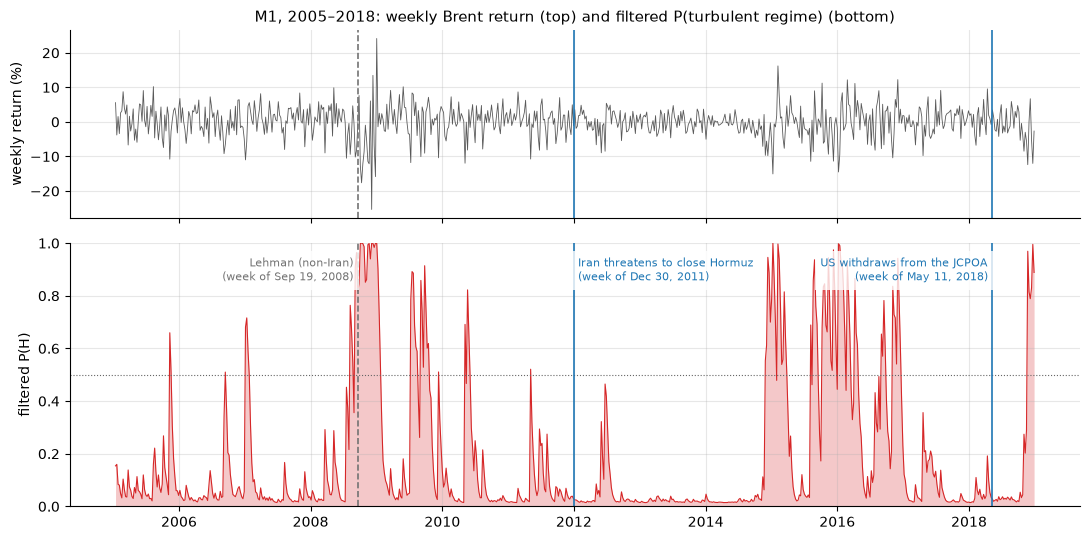

saved rq1_filtered_prob_2005_2018.png


In [5]:
# ── FIGURE: FILTERED P(TURBULENT) WITH THE IRAN EVENT WEEKS ────────────────────────────
start, end = design.dates[0], design.dates[-1]
# Iran events (config.EVENTS) inside the sample, each moved to its Friday; label = text before the ";".
iran_in = [(W.week_ending(pd.Timestamp(d)), lab.split(";")[0]) for _, d, lab, _ in C.EVENTS
           if start <= W.week_ending(pd.Timestamp(d)) <= end]
# Non-Iran reference events inside the sample (only Lehman, Sep 2008).
other_in = [(W.week_ending(pd.Timestamp(d)), eid.split("_")[0].capitalize() + " (non-Iran)")
            for eid, d in C.NON_IRAN_EVENTS if start <= W.week_ending(pd.Timestamp(d)) <= end]
print(f"Iran events inside {start.date()} -> {end.date()}: {len(iran_in)} of {len(C.EVENTS)}")
for wk, lab in iran_in + other_in:
    print(f"  week ending {wk.date()}: {lab:35s} filtered P(H) that week = {xi_H.loc[wk]:.2f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
# Top: the weekly return, so the turbulent spells can be seen in the raw data.
ax1.plot(design.y.index, design.y.values, lw=0.6, color="0.35")
ax1.set_ylabel("weekly return (%)")
ax1.set_title("M1, 2005–2018: weekly Brent return (top) and filtered P(turbulent regime) (bottom)")
# Bottom: filtered P(H); the dotted line at 0.5 is the "more likely than not" cut used for weeks per regime.
ax2.fill_between(xi_H.index, xi_H.values, color="tab:red", alpha=0.25, lw=0)
ax2.plot(xi_H.index, xi_H.values, color="tab:red", lw=0.8)
ax2.axhline(0.5, color="0.4", ls=":", lw=0.8)
ax2.set_ylim(0, 1)
ax2.set_ylabel("filtered P(H)")


def mark(wk, lab, color, ls, y, left=False):
    """Vertical line on both panels plus a label, written to the right of the line unless left=True
    (or the line is near the right edge of the plot)."""
    for ax in (ax1, ax2):
        ax.axvline(wk, color=color, ls=ls, lw=1.2)
    right = left or wk > end - pd.Timedelta(days=3 * 365)
    ax2.text(wk + pd.Timedelta(days=-25 if right else 25), y, f"{lab}\n(week of {wk:%b %d, %Y})",
             ha="right" if right else "left", va="top", fontsize=8, color=color,
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))


for wk, lab in iran_in:
    mark(wk, lab, "tab:blue", "-", 0.95)
for wk, lab in other_in:
    mark(wk, lab, "0.45", "--", 0.95, left=True)     # left of the line: the 2008-09 spike is to its right
fig.tight_layout()
out = plots.save_fig(fig, "rq1_filtered_prob_2005_2018")
plt.show()
print(f"saved {out.name}")

**M1 regimes: what we found**
- **Calm regime (N):** average return **+0.42% per week**, weekly volatility **3.6%** (about 26% per year). A calm spell lasts about **60 weeks** on average. 618 of the 729 weeks are calm.
- **Turbulent regime (H):** average return **−1.76% per week**, weekly volatility **7.3%** (about 53% per year), so **twice as volatile**. A turbulent spell lasts about **15 weeks**. 111 weeks are turbulent.
- **Switching:** in any calm week there is a 1.7% chance of turning turbulent the next week; in a turbulent week a 6.9% chance of calming down.
- **Memory (φ):** tiny in both regimes (0.045 and 0.023) and not significant: last week's return tells almost nothing about this week's.
- **The figure:** the turbulent regime shows up in the big oil crises: the 2008–09 crash (Lehman week: P(H) = 0.82), short bursts in 2009–10, the 2014–16 oil glut and 2016–17, and the oil sell-off at the end of 2018. At the two Iran events in this window (Hormuz threat Dec 2011, US leaving the nuclear deal May 2018) P(H) was only 0.03: the market stayed calm.

## 3 · Are two regimes better than one?

We compare M1 with the simplest alternative: **one regime**, i.e. the same formula with one μ, one φ and one σ² for all weeks (fitted with ordinary least squares).

**Three numbers:**
1. **LR (likelihood ratio)** = 2 × (fit of two regimes − fit of one regime), where "fit" is the log-likelihood. A bigger LR means two regimes fit much better.
   - ⚠️ The usual χ² p-value for an LR is **wrong here**. If there really is only one regime, the second regime's parameters mean nothing, and the textbook χ² rule needs every parameter to mean something. So the LR is shown, but not its textbook p-value.
2. **BIC** = a fit score that also punishes extra parameters. **Lower is better.** If two regimes still win after the penalty, that is evidence for two regimes.
3. **Bootstrap (the correct p-value).**
   - Pretend there is only one regime: simulate B = 199 fake 729-week histories from the fitted one-regime model.
   - On each fake history, fit both models and compute the LR.
   - This shows how big the LR gets *by pure chance* when there is only one regime.
   - p-value = the share of fake LRs that are at least as big as the real one. A small p means the real LR is too big to be chance, so there are two regimes.
   - Some fake fits are **degenerate** (one regime collapses). That is normal on one-regime data; they stay in the calculation and their number is printed next to the p-value. A fake fit that crashes completely is left out (`n_failed`).

**Practical:** the simulations are saved in `results/tables/rq1_bootstrap_draws.csv` and reused on the next run (set `FORCE_BOOT = True` to redo them). A fresh run takes about 1–3 minutes; the cell prints an estimate first.

In [6]:
# ── PLAIN LR AND BIC: ONE REGIME (AR(1)) VS TWO REGIMES (M1) ──────────────────────────
# One-regime Gaussian AR(1) by OLS. Its llf is the exact Gaussian log-likelihood with sigma2 = SSR/n.
ols = sm.OLS(design.y.values, sm.add_constant(design.X["r_lag"].values)).fit()
ll_one, k_one = float(ols.llf), 3                         # free parameters: intercept, phi, sigma2
k_two = len(m1.params) - len(m1.fixed)                    # 8: p00, p10, mu_N/H, phi_N/H, sigma2_N/H
lr_plain = 2 * (m1.loglike - ll_one)
df_plain = k_two - k_one
p_naive = float(chi2.sf(lr_plain, df_plain))              # NOT valid (see the text above); reference only
bic_one = k_one * np.log(n) - 2 * ll_one
bic_two = float(I.fit_summary(m1, n)["bic"])

one_two = pd.DataFrame({"loglike": [ll_one, m1.loglike], "free params k": [k_one, k_two],
                        "BIC (lower = better)": [bic_one, bic_two]},
                       index=["one regime: AR(1)", "two regimes: M1"])
display(one_two.round(2))
print(f"plain LR = {lr_plain:.2f} on {df_plain} extra parameters "
      f"(naive chi2 p = {p_naive:.2g}, not valid here; the bootstrap below is the real test)")
print(f"BIC prefers: {'two regimes' if bic_two < bic_one else 'one regime'} "
      f"(difference {bic_one - bic_two:.1f} in favour of {'M1' if bic_two < bic_one else 'AR(1)'})")

,loglike,free params k,BIC (lower = better)
one regime: AR(1),-2144.60,3,4308.98
two regimes: M1,-2091.79,8,4236.31


plain LR = 105.62 on 5 extra parameters (naive chi2 p = 3.4e-21, not valid here; the bootstrap below is the real test)
BIC prefers: two regimes (difference 72.7 in favour of M1)


In [7]:
# ── PARAMETRIC BOOTSTRAP OF THE LR (saved and reloaded) ────────────────────────────────
DRAWS = paths.TABLES / "rq1_bootstrap_draws.csv"
saved = pd.read_csv(DRAWS) if (DRAWS.exists() and not FORCE_BOOT) else None
# Reuse saved draws only if they were made for the same requested B (protects against a stale file).
if saved is not None and int(saved["B_requested"].iloc[0]) != B:
    print(f"saved draws were made for B = {int(saved['B_requested'].iloc[0])}, now B = {B} -> rerunning "
          "(delete the CSV or keep B at 199 to reuse)")
    saved = None
# ... and only if they came from the same M1 fit as section 2 (the saved two-regime log-likelihood must match).
if saved is not None and abs(float(saved["ll_two"].iloc[0]) - m1.loglike) > 1e-3:
    print(f"saved draws used a different M1 fit (loglike {float(saved['ll_two'].iloc[0]):.4f} vs "
          f"{m1.loglike:.4f} now) -> rerunning the bootstrap")
    saved = None

if saved is not None:
    print(f"reloaded {len(saved)} bootstrap draws from {DRAWS.name} (set FORCE_BOOT = True to redo)")
else:
    B_requested, boot_note = B, ""
    # Timing guard: one call = the real-data fit + 1 replicate, so B x (one call) overstates the total a bit.
    t0 = time.perf_counter()
    I.bootstrap_lr_1v2(design.y, design.X, n_reps=1, seed=C.SEED, search_reps=C.SEARCH_REPS_FIRST)
    t_one = time.perf_counter() - t0
    est_min = B * t_one / 60
    print(f"one replicate (timed together with one extra fit of the real data): {t_one:.1f} s "
          f"-> about {est_min:.1f} min for B = {B} (an upper bound)")
    if est_min > BOOT_GUARD_MIN and B > 99:
        boot_note = f"B reduced from {B} to 99 by the {BOOT_GUARD_MIN}-min timing guard"
        print(f"TOO SLOW: {boot_note}")
        B = 99
    t0 = time.perf_counter()
    boot = I.bootstrap_lr_1v2(design.y, design.X, n_reps=B, seed=C.SEED, search_reps=C.SEARCH_REPS_FIRST)
    print(f"bootstrap done in {(time.perf_counter() - t0) / 60:.1f} min")
    # One row per replicate (lr_boot is NaN for a failed replicate); the summary is repeated in every row
    # so the file is self-contained.
    saved = pd.DataFrame({"rep": np.arange(B), "seed": C.SEED + np.arange(B), "lr_boot": boot["lr_boot"]})
    saved = saved.assign(lr_obs=boot["lr"], ll_one=boot["ll_one"], ll_two=boot["ll_two"],
                         n_degenerate=boot["n_degenerate"], degenerate_obs=boot["degenerate_obs"],
                         B_requested=B_requested, note=boot_note)
    paths.TABLES.mkdir(parents=True, exist_ok=True)
    saved.to_csv(DRAWS, index=False)
    print(f"saved {DRAWS.name}")

# Summary, recomputed from the draws (same formula as insample.bootstrap_lr_1v2).
lr_boot = saved["lr_boot"].to_numpy(dtype=float)
lr_obs = float(saved["lr_obs"].iloc[0])
valid = ~np.isnan(lr_boot)
B_used, n_valid, n_failed = len(lr_boot), int(valid.sum()), int((~valid).sum())
n_deg = int(saved["n_degenerate"].iloc[0])
boot_note = "" if pd.isna(saved["note"].iloc[0]) else str(saved["note"].iloc[0])
p_boot = (1 + int(np.sum(lr_boot[valid] >= lr_obs))) / (n_valid + 1)

print(f"\nobserved LR = {lr_obs:.2f}  (plain LR from the M1 fit above: {lr_plain:.2f})")
print(f"bootstrap p = {p_boot:.4f}   |   n_degenerate = {n_deg} of {B_used}   |   valid = {n_valid}, failed = {n_failed}")
print(f"simulated LR under one regime: median {np.nanmedian(lr_boot):.2f}, 95th pct {np.nanpercentile(lr_boot, 95):.2f}, "
      f"max {np.nanmax(lr_boot):.2f}")
print(f"real-data two-regime fit degenerate: {bool(saved['degenerate_obs'].iloc[0])}")
if boot_note:
    print(f"NOTE: {boot_note}")

one replicate (timed together with one extra fit of the real data): 0.7 s -> about 2.3 min for B = 199 (an upper bound)
bootstrap done in 1.0 min
saved rq1_bootstrap_draws.csv

observed LR = 105.62  (plain LR from the M1 fit above: 105.62)
bootstrap p = 0.0050   |   n_degenerate = 174 of 199   |   valid = 199, failed = 0
simulated LR under one regime: median 7.42, 95th pct 16.86, max 26.99
real-data two-regime fit degenerate: False


**1 vs 2 regimes: what we found**
- **Two regimes fit much better.** LR = 105.6.
- **The bootstrap confirms it.** In 199 fake histories where there is only one regime, the LR was typically about 7 (95% of them below 17, the largest 27). None came close to 105.6, so **p = 0.005**, the smallest p-value possible with 199 simulations.
- **BIC agrees:** 4,236 for two regimes vs 4,309 for one (lower is better), even after the penalty for the 5 extra parameters.
- 174 of the 199 fake two-regime fits were degenerate. That is expected: on data with only one regime, a "second regime" usually collapses.
- **Conclusion:** weekly Brent returns clearly switch between a calm and a turbulent regime.

## 4 · Do μ and φ differ between the regimes? The φ decision

**Why this matters:** every later model needs one fixed choice: either one φ shared by both regimes, or a separate φ for each regime. We decide it here, once, on 2005–2018, and then freeze it.

**Two tests for each parameter (μ and φ):**
- **LR test:** refit M1 with μ forced to be the same in both regimes, and compare the fit with the free M1. Then the same for φ. If forcing them equal makes the fit much worse (small p-value), they really differ. Here the normal χ² p-value is fine, because both regimes still exist and only one number is tied.
- **Wald test:** a second opinion from the free fit only: is the difference between the two estimates big compared with its uncertainty?

**The decision rule (fixed in advance):** φ gets a separate value per regime (`PHI_SWITCHING = True`) only if the LR test for φ has p < 0.05. Otherwise both regimes share one φ (`False`). The decision is written to `results/frozen/rq1_decision.json`.

**Same-fit check:** the tests refit M1 themselves. The cell checks that they used the same M1 as section 2 and stops if not.

**Your step:** read the decision line.
- If you agree: open `src/brent/config.py`, set `PHI_SWITCHING = True` or `False` to match, then Restart & Run All.
- To overrule the rule: set `PHI_OVERRIDE` and `OVERRIDE_REASON` in the cell below (the reason is saved in the JSON).

In [8]:
# ── EQUALITY TESTS FOR μ AND φ, THEN THE φ DECISION ────────────────────────────────────
eq = I.equality_tests(design, spec_m1)          # rows mu, phi; refits M1 with seed C.SEED
eq_show = eq.rename(columns={"est_N": "estimate N", "est_H": "estimate H", "lr": "LR", "p_lr": "p (LR)",
                             "wald": "Wald", "p_wald": "p (Wald)", "lr_raw": "LR before clipping at 0"})
display(eq_show.round(4))

phi_lr, phi_p, phi_df = float(eq.loc["phi", "lr"]), float(eq.loc["phi", "p_lr"]), int(eq.loc["phi", "df"])

# Same-fit check. The equality tests and the bootstrap refit M1 themselves with seed C.SEED. If section 2
# had to fall back to another seed, the decision and the tables could rest on different M1 fits.
same_fit = {"loglike (bootstrap refit vs section 2)": (float(saved["ll_two"].iloc[0]), m1.loglike),
            "mu_N (equality tests vs section 2)": (float(eq.loc["mu", "est_N"]), rd["mu_N"]),
            "mu_H (equality tests vs section 2)": (float(eq.loc["mu", "est_H"]), rd["mu_H"]),
            "phi_N (equality tests vs section 2)": (float(eq.loc["phi", "est_N"]), rd["phi_N"]),
            "phi_H (equality tests vs section 2)": (float(eq.loc["phi", "est_H"]), rd["phi_H"])}
for what, (a, b) in same_fit.items():
    if abs(a - b) > 1e-3:
        print(f"WARNING: {what} differ: {a:.4f} vs {b:.4f}. The tests did not use the same M1 fit as section 2.")
assert SEED_M1 == C.SEED, ("The M1 in section 2 came from a fallback seed, but the equality tests and the bootstrap "
                           "refit M1 with C.SEED. Resolve this (discuss) before making the phi decision.")
print("same-fit check OK: the equality tests and the bootstrap use the same M1 as section 2")
rule_says = bool(phi_p < 0.05)                  # the pre-registered rule: reject phi_N = phi_H at 5% -> switching

# ── OVERRIDE (leave as None to follow the rule) ──
PHI_OVERRIDE = None        # True or False only if you overrule the rule after looking at the results
OVERRIDE_REASON = ""       # required when PHI_OVERRIDE is set; stored in the JSON

decision = {"phi_switching": rule_says if PHI_OVERRIDE is None else bool(PHI_OVERRIDE),
            "lr_stat": phi_lr, "p_value": phi_p, "df": phi_df, "sample_end": C.RQ1_END,
            "git_hash": paths.git_hash(),
            "rule": "phi_switching = (LR p-value of phi_N = phi_H in M1 on 2005-2018) < 0.05"}
if PHI_OVERRIDE is not None:
    assert OVERRIDE_REASON.strip(), "set OVERRIDE_REASON when you override the rule"
    decision["override"] = {"rule_result": rule_says, "reason": OVERRIDE_REASON.strip()}
paths.FROZEN.mkdir(parents=True, exist_ok=True)
(paths.FROZEN / "rq1_decision.json").write_text(json.dumps(decision, indent=2) + "\n")

print(f"mu : N {eq.loc['mu', 'est_N']:.3f} vs H {eq.loc['mu', 'est_H']:.3f}   "
      f"LR {eq.loc['mu', 'lr']:.3f} (p {eq.loc['mu', 'p_lr']:.4f}),  Wald p {eq.loc['mu', 'p_wald']:.4f}")
print(f"phi: N {eq.loc['phi', 'est_N']:.3f} vs H {eq.loc['phi', 'est_H']:.3f}   "
      f"LR {phi_lr:.3f} (p {phi_p:.4f}),  Wald p {eq.loc['phi', 'p_wald']:.4f}")
print(f"\nrule: p = {phi_p:.4f} {'<' if rule_says else '>='} 0.05 -> phi_switching = {rule_says}"
      + ("" if PHI_OVERRIDE is None else f"; OVERRIDDEN to {decision['phi_switching']} ({OVERRIDE_REASON})"))
print(f"wrote results/frozen/rq1_decision.json (git {decision['git_hash']})")

,estimate N,estimate H,LR,df,p (LR),Wald,p (Wald),LR before clipping at 0
mu,0.4159,-1.7558,7.6592,1,0.0056,5.4191,0.0199,7.6592
phi,0.0449,0.0228,0.0375,1,0.8464,0.0368,0.8480,0.0375


same-fit check OK: the equality tests and the bootstrap use the same M1 as section 2
mu : N 0.416 vs H -1.756   LR 7.659 (p 0.0056),  Wald p 0.0199
phi: N 0.045 vs H 0.023   LR 0.038 (p 0.8464),  Wald p 0.8480

rule: p = 0.8464 >= 0.05 -> phi_switching = False
wrote results/frozen/rq1_decision.json (git f11da5b)


**φ decision: what we found**
- **The average return μ differs between the regimes** (LR p = 0.006, Wald p = 0.02): calm weeks average +0.42%, turbulent weeks −1.76%. Turbulent spells are mostly periods of falling prices.
- **φ does not differ** (LR p = 0.85, Wald p = 0.85): 0.045 vs 0.023, both close to zero.
- **Decision (by the rule fixed in advance): `PHI_SWITCHING = False`**, so all later models use one φ shared by both regimes. Saved in `results/frozen/rq1_decision.json`; to be copied into `config.py`.

## 5 · Rehearsal: M1 → M2 → M3 on 2005–2018

Notebook 04 fits these models on 2005–2025 to answer RQ2. Here we try them first on the RQ1 years to catch problems early. They use the φ choice from section 4.

| Model | What changes the chance of switching regimes |
|---|---|
| M1 | nothing: fixed probabilities |
| M2 | last week's GPR, VIX and volatility (`log_rv`), all z-scored |
| M3 | M2 + last week's Iran news share (`iran_gdelt`). Iran news may only change the chance of going **calm → turbulent**; its effect on turbulent → calm is fixed at 0 |

**What the next cells show and check:**
- **Each bigger model fits at least as well as the smaller one**: LL(M3) ≥ LL(M2) ≥ LL(M1). This must hold because each bigger model contains the smaller one. If it fails, the optimizer got stuck: the cell retries once with another seed and stops if it still fails.
- **β = Iran's coefficient** for calm → turbulent. β > 0 means more Iran news last week gives a higher chance of turning turbulent this week. Its standard error (SE) shows how uncertain β is; "n/a (flat likelihood)" means the data cannot pin it down.
- **Near-separation warning:** a coefficient bigger than 50 (in absolute value) means a variable almost perfectly predicts the switches in these years. The direction is meaningful, but the size and its SE are not reliable.
- **M3 vs M2 LR test** (1 degree of freedom, because M3 adds one coefficient): does adding Iran news improve the fit significantly?

This is a rehearsal; the real RQ2 answer comes from notebook 04.

In [9]:
# ── WHICH φ? (the frozen decision, or the JSON while your OK is pending) ───────────────
decision = json.loads((paths.FROZEN / "rq1_decision.json").read_text())
if C.PHI_SWITCHING is None:
    PHI = bool(decision["phi_switching"])
    print(f"Decision pending your OK: set PHI_SWITCHING = {PHI} in src/brent/config.py by hand, "
          "then Restart & Run All.")
else:
    assert C.PHI_SWITCHING == decision["phi_switching"], (
        f"config.PHI_SWITCHING = {C.PHI_SWITCHING} but rq1_decision.json says {decision['phi_switching']}")
    PHI = C.PHI_SWITCHING
    print(f"PHI_SWITCHING = {PHI} (config.py matches rq1_decision.json)")

Decision pending your OK: set PHI_SWITCHING = False in src/brent/config.py by hand, then Restart & Run All.


In [10]:
# ── FIT THE LADDER M1 -> M2 -> M3 ON 2005-2018 AND CHECK THE NESTING ───────────────────
# Each bigger model gets two kinds of start: a fresh random search AND the smaller model's optimum
# (with the new coefficients at 0), so it can never end up below the smaller model if the optimizer works.
t0 = time.perf_counter()
ladder = I.fit_ladder(panel, C.RQ1_END, PHI)
print(f"ladder fitted in {time.perf_counter() - t0:.1f} s (variant: {C.M3_VARIANT})")


def ensure_nested(child, parent):
    """If LL(child) < LL(parent), retry the child once with seed + 1 (plus the nesting start); stop if still below."""
    if ladder[child].loglike >= ladder[parent].loglike - 1e-6:
        return
    print(f"LL({child}) = {ladder[child].loglike:.3f} < LL({parent}) = {ladder[parent].loglike:.3f}: "
          f"retrying {child} with seed {C.SEED + 1}")
    sp = ladder[child].spec
    mdl = ms.make_model(D.build_design(panel, sp, C.RQ1_END), sp)
    alt = ms.fit_model(mdl, sp, None, C.SEARCH_REPS_FIRST, 0, C.SEED + 1, (ms.nest_start(ladder[parent], mdl, sp),))
    print(f"  retry: LL = {alt.loglike:.3f}")
    if alt.loglike > ladder[child].loglike:
        ladder[child] = alt
    if ladder[child].loglike < ladder[parent].loglike - 1e-6:
        raise RuntimeError(f"LL({child}) < LL({parent}) even after the retry (risk R5). Stop and discuss.")


ensure_nested("M2", "M1")
ensure_nested("M3", "M2")

# Summary per model. Durations are evaluated at average regressor values (all z-scores = 0); a duration of
# inf means P(staying) rounds to exactly 1 there, so numpy's divide-by-zero warning is silenced and explained.
with np.errstate(divide="ignore"):
    lad_tab = pd.DataFrame({k: I.fit_summary(f, len(f.model.endog)) for k, f in ladder.items()}).T
lad_tab = lad_tab[["loglike", "k", "bic", "dur_N", "dur_H", "sigma2_N", "sigma2_H"]].astype(float).round(3)
lad_tab["k"] = lad_tab["k"].astype(int)
lad_tab["converged"] = [f.converged for f in ladder.values()]
lad_tab["degenerate"] = [f.degenerate for f in ladder.values()]
# Flag every degenerate or non-converged ladder fit (the checks cell at the end fails on them).
for k, f in ladder.items():
    if f.degenerate or not f.converged:
        what = " and ".join(w for w, flag in (("DEGENERATE", f.degenerate), ("NOT CONVERGED", not f.converged)) if flag)
        print(f"!! {k} is {what} (LL {f.loglike:.3f}, {f.n_warnings} warnings): do not read its results; discuss first")
if not any(f.degenerate or not f.converged for f in ladder.values()):
    print("every ladder fit converged and none is degenerate.")
display(lad_tab.rename(columns={"k": "free params", "dur_N": "duration N (wk)", "dur_H": "duration H (wk)"}))
for k in ladder:
    for s in ("N", "H"):
        if not np.isfinite(lad_tab.loc[k, f"dur_{s}"]):
            print(f"NOTE {k}: duration {s} = inf at average regressor values: the model (almost) never leaves "
                  f"regime {s} unless the regressors move away from average (see near-separation below)")

ll = {k: f.loglike for k, f in ladder.items()}
assert ll["M3"] >= ll["M2"] - 1e-6 and ll["M2"] >= ll["M1"] - 1e-6, ll
print(f"nesting OK: LL M1 {ll['M1']:.3f} <= M2 {ll['M2']:.3f} <= M3 {ll['M3']:.3f}")
if C.M3_VARIANT == "constrained":
    fixed_val = ladder["M3"].params["p[1->0].tvtp4"]        # Iran in the turbulent -> calm logit
    assert ladder["M3"].model.tvtp_name_map[C.IRAN_VAR] == 4 and fixed_val == 0.0, fixed_val
    print(f"constraint OK: Iran coefficient in the turbulent -> calm logit = {fixed_val} (exactly 0)")

ladder fitted in 5.1 s (variant: constrained)
every ladder fit converged and none is degenerate.


,loglike,free params,bic,duration N (wk),duration H (wk),sigma2_N,sigma2_H,converged,degenerate
M1,-2091.808,7,4229.757,59.827,14.652,12.784,52.978,True,False
M2,-2084.357,13,4254.406,9.371,inf,10.794,48.664,True,False
M3,-2082.986,14,4258.256,10.379,inf,10.604,48.758,True,False


NOTE M2: duration H = inf at average regressor values: the model (almost) never leaves regime H unless the regressors move away from average (see near-separation below)
NOTE M3: duration H = inf at average regressor values: the model (almost) never leaves regime H unless the regressors move away from average (see near-separation below)
nesting OK: LL M1 -2091.808 <= M2 -2084.357 <= M3 -2082.986
constraint OK: Iran coefficient in the turbulent -> calm logit = 0.0 (exactly 0)


In [11]:
# ── β (DECK SIGNS), ITS SE, ALL TRANSITION COEFFICIENTS, AND THE M3 vs M2 LR TEST ──────
m3 = ladder["M3"]
tv3 = list(m3.model.tvtp_name_map)                          # transition regressors in statsmodels' order
deck3 = ms.transition_coefs_deck(m3.params, tv3)            # rows N->H, H->N in the deck's sign convention
cov3 = ms.param_cov(m3.model, m3.params, m3.fixed)          # covariance of the free parameters
beta_name = f"p[0->0].tvtp{m3.model.tvtp_name_map[C.IRAN_VAR]}"   # statsmodels name behind β (looked up by name)
beta = float(deck3.loc["N->H", C.IRAN_VAR])
se_beta = float(np.sqrt(cov3.loc[beta_name, beta_name])) if beta_name in cov3.index else np.nan
if np.isfinite(se_beta):
    z = beta / se_beta
    print(f"beta (Iran news -> calm-to-turbulent switch, deck sign) = {beta:.3f}, SE {se_beta:.3f}, "
          f"z {z:.2f}, p {2 * norm.sf(abs(z)):.3f}")
else:
    print(f"beta (Iran news -> calm-to-turbulent switch, deck sign) = {beta:.3f}, SE n/a (flat likelihood)")

# Every transition coefficient of M2 and M3 with its SE (deck signs; SE NaN = could not be computed).
coefs = pd.concat([I.coef_table(ladder[k], k) for k in ("M2", "M3")], ignore_index=True)
coefs["se"] = coefs["se"].map(lambda v: f"{v:.3f}" if np.isfinite(v) else "n/a (flat likelihood)")
coefs["flag"] = np.where(coefs["coef"].abs() > 50, "NEAR-SEPARATION", "")
display(coefs[["model", "logit", "var", "coef", "se", "z", "p", "fixed", "flag"]].round(3))
if (coefs["flag"] != "").any():
    print("NEAR-SEPARATION (|coef| > 50): a regressor almost perfectly predicts switches; "
          "treat that coefficient as unreliable.")
    for _, r in coefs[coefs["flag"] != ""].iterrows():
        print(f"   {r['model']} {r['logit']} {r['var']}: {r['coef']:.1f}")

# LR test M3 vs M2: df = number of free parameters added, computed from the fits (never typed in).
lr23 = I.lr_test(ladder["M2"], m3)
print(f"\nLR M3 vs M2 = {lr23['stat']:.3f}, df = {lr23['df']}, p = {lr23['pvalue']:.4f}")
assert lr23["df"] == (1 if C.M3_VARIANT == "constrained" else 2), lr23

beta (Iran news -> calm-to-turbulent switch, deck sign) = -0.415, SE 0.254, z -1.63, p 0.103


,model,logit,var,coef,se,z,p,fixed,flag
0,M2,N->H,const,-2.125,n/a (flat likelihood),NaN,NaN,False,
1,M2,N->H,gpr,-0.484,n/a (flat likelihood),NaN,NaN,False,
2,M2,N->H,vix,-0.868,n/a (flat likelihood),NaN,NaN,False,
3,M2,N->H,log_rv,1.919,n/a (flat likelihood),NaN,NaN,False,
4,M2,H->N,const,-43.701,n/a (flat likelihood),NaN,NaN,False,
5,M2,H->N,gpr,-735.502,n/a (flat likelihood),NaN,NaN,False,NEAR-SEPARATION
6,M2,H->N,vix,-872.137,n/a (flat likelihood),NaN,NaN,False,NEAR-SEPARATION
7,M2,H->N,log_rv,237.820,n/a (flat likelihood),NaN,NaN,False,NEAR-SEPARATION
8,M3,N->H,const,-2.238,0.516,-4.338,0.000,False,
9,M3,N->H,gpr,-0.396,0.287,-1.383,0.167,False,


NEAR-SEPARATION (|coef| > 50): a regressor almost perfectly predicts switches; treat that coefficient as unreliable.
   M2 H->N gpr: -735.5
   M2 H->N vix: -872.1
   M2 H->N log_rv: 237.8
   M3 H->N gpr: -735.5
   M3 H->N vix: -872.1
   M3 H->N log_rv: 237.8

LR M3 vs M2 = 2.742, df = 1, p = 0.0978


**Rehearsal M1 → M2 → M3: what we found (2005–2018 only; the real RQ2 answer is notebook 04)**
- **All fits worked:** every fit converged, none is degenerate, and each bigger model fits at least as well as the smaller one.
- **Iran news (M3):** β = **−0.42** (SE 0.25, p = 0.10), and adding Iran news to M2 gives LR = 2.74 (p = 0.10). **Not significant**; if anything the sign leans negative, because Iran coverage was highest in calm years (e.g. the 2006–07 nuclear standoff).
- **What does predict turning turbulent:** last week's volatility (coefficient +1.77, p < 0.001). VIX comes out negative (p = 0.049), probably because VIX and last week's volatility partly measure the same thing (correlation 0.38), so their separate effects are hard to split.
- **BIC prefers the simple M1** (4,230 vs 4,254 for M2 and 4,258 for M3): on 2005–2018 the extra variables do not improve the fit enough to pay for their parameters.
- ⚠️ **Problem to fix before forecasting:** in M2 and M3 the turbulent → calm coefficients blow up (−735, −872, +238). With only about 7–8 turbulent spells in these years, those variables almost perfectly "predict" when turbulence ends, so the model thinks a turbulent spell never ends at average values (duration = ∞) and says P(turbulent) = 1.000 at the end of 2018. Those coefficients are unreliable; a fix is decided before notebook 05.

## 6 · Does our own forecasting code give the right numbers?

- Notebook 05 makes 723 one-week-ahead forecasts with our own code (`forecast.py`). Its core is the probability of each regime next week, using data up to this week.
- Here we compare our numbers with statsmodels' own numbers for M1, M2 and M3. They must agree to 10 decimal places (difference below 1e-10).
- (statsmodels only gives these numbers inside its "smooth" results object; we read just that one field, which uses data up to the previous week only, never the smoothed probabilities.)
- Then one real example: standing on Fri Dec 28, 2018, M3 forecasts the week ending Jan 4, 2019. It shows the chance of turbulence, the expected variance, and the chance of a "big move" (bigger than the 90th percentile of weekly moves in 2005–2012).

In [12]:
# ── FORECASTER CHECK: OUR predicted_probs VS STATSMODELS ───────────────────────────────
fc_diff = {}
for k, f in ladder.items():
    ours = F.predicted_probs(f.model, f.params.values)
    theirs = np.asarray(f.model.smooth(f.params.values).predicted_marginal_probabilities)
    fc_diff[k] = float(np.max(np.abs(ours - theirs)))
    print(f"{k}: max |ours - statsmodels| = {fc_diff[k]:.1e}")
assert max(fc_diff.values()) < 1e-10, fc_diff

# One real one-step forecast with M3 from the last 2018 week (uses data dated <= Dec 28, 2018 only).
d3 = D.build_design(panel, m3.spec, C.RQ1_END)
thr = F.highvol_threshold(panel)
o = F.one_step(m3, d3, thr)
print(f"\nM3 forecast for the week after {d3.origin.date()}  (thr = {thr:.2f}%):")
print(f"  filtered P(H) at the origin   {o.xi_H_origin:.3f}")
print(f"  P(H) next week (pi_H)         {o.pi_H:.3f}")
print(f"  forecast mean return          {o.mean_fc:.3f} %")
print(f"  forecast E[r^2] (var_fc)      {o.var_fc:.2f} %^2   (sd {np.sqrt(o.var_fc):.2f} %)")
print(f"  P(|r| > thr)                  {o.p_exceed:.3f}")

M1: max |ours - statsmodels| = 6.1e-16
M2: max |ours - statsmodels| = 2.2e-16
M3: max |ours - statsmodels| = 2.2e-16

M3 forecast for the week after 2018-12-28  (thr = 7.88%):
  filtered P(H) at the origin   1.000
  P(H) next week (pi_H)         1.000
  forecast mean return          -1.480 %
  forecast E[r^2] (var_fc)      50.93 %^2   (sd 7.14 %)
  P(|r| > thr)                  0.269


## 7 · Save the tables

- `rq1_tests.csv`: one row per test (`1v2_lr`, `1v2_bootstrap`, `bic_one`, `bic_two`, `mu_equal`, `phi_equal`) with the test statistic, degrees of freedom, p-value and a short note. For the two BIC rows, the df column holds the number of parameters. The bootstrap note says how many simulations were run and how many were degenerate.
- `rq1_params_M1.csv`: M1's parameters with readable names and standard errors, plus the average duration and the number of weeks of each regime.

In [13]:
# ── SAVE rq1_tests.csv AND rq1_params_M1.csv ───────────────────────────────────────────
boot_txt = (f"parametric bootstrap, B={B_used} (valid {n_valid}, failed {n_failed}), n_degenerate={n_deg}"
            + (f"; {boot_note}" if boot_note else ""))
wald_txt = lambda k: (f"LR chi2(1); Wald={eq.loc[k, 'wald']:.3f}, p_wald={eq.loc[k, 'p_wald']:.4f}; "
                      f"est_N={eq.loc[k, 'est_N']:.4f}, est_H={eq.loc[k, 'est_H']:.4f}")
tests = pd.DataFrame([
    ("1v2_lr", lr_plain, df_plain, p_naive,
     f"naive chi2({df_plain}) p, NOT valid (regime-2 parameters unidentified under one regime); use 1v2_bootstrap"),
    ("1v2_bootstrap", lr_obs, np.nan, p_boot, boot_txt),
    ("bic_one", bic_one, k_one, np.nan, "BIC, one-regime Gaussian AR(1); df = free parameters"),
    ("bic_two", bic_two, k_two, np.nan, "BIC, M1 (mu, phi, sigma2 switching); df = free parameters"),
    ("mu_equal", float(eq.loc["mu", "lr"]), int(eq.loc["mu", "df"]), float(eq.loc["mu", "p_lr"]), wald_txt("mu")),
    ("phi_equal", phi_lr, phi_df, phi_p, wald_txt("phi") + f"; decision phi_switching={decision['phi_switching']}"
     + (f"; OVERRIDE: {decision['override']['reason']}" if "override" in decision else "")),
], columns=["test", "stat", "df", "pvalue", "note"])
paths.save_table(tests, "rq1_tests")
display(tests.round(4))

# M1 parameters (readable names) with SEs, then the derived quantities (no SE).
par = pd.DataFrame({"name": [m1.model.readable[k] for k in m1.params.index], "value": m1.params.values,
                    "se": [se_m1.get(m1.model.readable[k], np.nan) for k in m1.params.index], "note": ""})
extra = pd.DataFrame([
    ("dur_N", dur["N"], np.nan, "expected duration, weeks"), ("dur_H", dur["H"], np.nan, "expected duration, weeks"),
    ("weeks_N", weeks["N"], np.nan, "weeks with filtered P(H) <= 0.5"),
    ("weeks_H", weeks["H"], np.nan, "weeks with filtered P(H) > 0.5"),
    ("loglike", m1.loglike, np.nan, f"seed {SEED_M1}, n = {n}, {design.dates[0].date()} to {design.dates[-1].date()}"),
], columns=["name", "value", "se", "note"])
params_m1 = pd.concat([par, extra], ignore_index=True)
paths.save_table(params_m1, "rq1_params_M1")
display(params_m1.round(4))
print("saved rq1_tests.csv and rq1_params_M1.csv")

,test,stat,df,pvalue,note
0,1v2_lr,105.6225,5.0,0.0000,"naive chi2(5) p, NOT valid (regime-2 parameters unidentified under one regime); use 1v2_bootstrap"
1,1v2_bootstrap,105.6225,NaN,0.0050,"parametric bootstrap, B=199 (valid 199, failed 0), n_degenerate=174"
2,bic_one,4308.9756,3.0,NaN,"BIC, one-regime Gaussian AR(1); df = free parameters"
3,bic_two,4236.3115,8.0,NaN,"BIC, M1 (mu, phi, sigma2 switching); df = free parameters"
4,mu_equal,7.6592,1.0,0.0056,"LR chi2(1); Wald=5.419, p_wald=0.0199; est_N=0.4159, est_H=-1.7558"
5,phi_equal,0.0375,1.0,0.8464,"LR chi2(1); Wald=0.037, p_wald=0.8480; est_N=0.0449, est_H=0.0228; decision phi_switching=False"


,name,value,se,note
0,p00,0.9835,0.0093,
1,p10,0.0686,0.0343,
2,mu_N,0.4159,0.1682,
3,mu_H,-1.7558,0.9052,
4,phi_N,0.0449,0.0443,
5,phi_H,0.0228,0.1008,
6,sigma2_N,12.8349,1.2474,
7,sigma2_H,53.2414,8.8108,
8,dur_N,60.5406,NaN,"expected duration, weeks"
9,dur_H,14.5684,NaN,"expected duration, weeks"


saved rq1_tests.csv and rq1_params_M1.csv


## 8 · Checks

Each line is an automatic check that stops the notebook if something is wrong. For example: H really has the bigger variance, the sample ends on Dec 28, 2018, each bigger model fits at least as well as the smaller one, no fit is degenerate, and our forecaster matches statsmodels.

One exception: until you set `PHI_SWITCHING` in `config.py`, that one check prints **PENDING** instead of failing (your OK is the missing step).

In [14]:
# ── CHECKS ─────────────────────────────────────────────────────────────────────────────
# 1. H (regime 1) has the higher variance in every reported fit.
for label, f in {"M1 (RQ1)": m1, **{f"{k} (ladder)": v for k, v in ladder.items()}}.items():
    assert f.params["sigma2[1]"] > f.params["sigma2[0]"], label
print("ok  H has the higher sigma2 in M1 (RQ1) and in the M1/M2/M3 ladder")

# 2. The RQ1 sample ends Dec 28, 2018 and has 729 rows.
assert D.build_design(panel, spec_m1, C.RQ1_END).dates[-1] == pd.Timestamp("2018-12-28") and n == 729
print("ok  design ends 2018-12-28 with 729 rows")

# 3. The decision file exists and is complete; config matches it (PENDING until you set it by hand).
dec = json.loads((paths.FROZEN / "rq1_decision.json").read_text())
assert {"phi_switching", "lr_stat", "p_value", "df", "sample_end", "git_hash"} <= set(dec)
assert dec["sample_end"] == "2018-12-28" and isinstance(dec["phi_switching"], bool)
print("ok  rq1_decision.json exists with all fields")
if C.PHI_SWITCHING is None:
    print(f"PENDING  config.PHI_SWITCHING is None: set it to {dec['phi_switching']} by hand, then Restart & Run All")
else:
    assert C.PHI_SWITCHING == dec["phi_switching"]
    print("ok  config.PHI_SWITCHING matches rq1_decision.json")

# 4. Log-likelihood nesting M1 <= M2 <= M3.
assert ladder["M3"].loglike >= ladder["M2"].loglike - 1e-6
assert ladder["M2"].loglike >= ladder["M1"].loglike - 1e-6
print("ok  LL(M1) <= LL(M2) <= LL(M3)")

# 4b. No ladder fit is degenerate or non-converged.
bad_lad = [k for k, f in ladder.items() if f.degenerate or not f.converged]
assert not bad_lad, f"ladder fit(s) {bad_lad} are degenerate or did not converge: do not use them; discuss first"
print("ok  M1, M2, M3 all converged and none is degenerate")

# 5. Our forecaster reproduces statsmodels' predicted probabilities.
assert max(fc_diff.values()) < 1e-10
print("ok  forecaster max diff < 1e-10 for M1, M2, M3")

# 6. M3 constraint and LR degrees of freedom.
if C.M3_VARIANT == "constrained":
    assert ladder["M3"].params["p[1->0].tvtp4"] == 0.0 and lr23["df"] == 1
    print("ok  M3 Iran coefficient in H->N is exactly 0; LR(M3 vs M2) df = 1")

# 7. Every output file was written.
for p in [paths.FROZEN / "rq1_decision.json", paths.FROZEN / "std_stats.csv", paths.TABLES / "rq1_tests.csv",
          paths.TABLES / "rq1_params_M1.csv", paths.TABLES / "rq1_bootstrap_draws.csv",
          paths.FIGURES / "rq1_filtered_prob_2005_2018.png"]:
    assert p.exists(), p
print("ok  all six output files exist")

ok  H has the higher sigma2 in M1 (RQ1) and in the M1/M2/M3 ladder
ok  design ends 2018-12-28 with 729 rows
ok  rq1_decision.json exists with all fields
PENDING  config.PHI_SWITCHING is None: set it to False by hand, then Restart & Run All
ok  LL(M1) <= LL(M2) <= LL(M3)
ok  M1, M2, M3 all converged and none is degenerate
ok  forecaster max diff < 1e-10 for M1, M2, M3
ok  M3 Iran coefficient in H->N is exactly 0; LR(M3 vs M2) df = 1
ok  all six output files exist


In [15]:
# ── SIZE BUDGET (last cell of every notebook) ──────────────────────────────────────────
paths.check_budget()
print("size budget OK")

size budget OK


**Before committing:** set `PHI_SWITCHING` in `config.py` (section 4), then Restart & Run All. The notebook, `config.py`, the decision JSON, `std_stats.csv`, the three tables and the figure are committed together.